In [1]:
!pip install -q optuna

In [2]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Pandas:", pd.__version__)
print("Optuna:", optuna.__version__)
print("Setup completed successfully.")

Pandas: 2.2.3
Optuna: 5.0.0
Setup completed successfully.


In [3]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

# Load cleaned RetailPulse dataset

from google.colab import drive
drive.mount('/content/drive')

file_path = DATA_DIR / "retail_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Mounted at /content/drive
Dataset shape: (410763, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
IsCancelled       bool
Revenue        float64
dtype: object


In [4]:
# Prepare daily product demand

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Remove invalid rows
df = df.dropna(subset=["InvoiceDate", "StockCode", "Quantity"])

# Exclude canceled transactions if the flag exists
if "IsCancelled" in df.columns:
    df = df[df["IsCancelled"] == 0]

# Retain valid positive sales quantities
df = df[df["Quantity"] > 0].copy()

# Aggregate quantity sold by product and day
daily = (
    df.groupby([
        "StockCode",
        pd.Grouper(key="InvoiceDate", freq="D")
    ])["Quantity"]
    .sum()
    .reset_index()
    .rename(columns={
        "InvoiceDate": "Date",
        "Quantity": "DailyDemand"
    })
)

print("Daily demand shape:", daily.shape)
display(daily.head())

Daily demand shape: (223833, 3)


,StockCode,Date,DailyDemand
0,10002,2009-12-01,12
1,10002,2009-12-03,6
2,10002,2009-12-04,73
3,10002,2009-12-06,49
4,10002,2009-12-07,2


In [5]:
# Create features for one product

# Select the product with the highest total sales quantity
selected_product = (
    daily.groupby("StockCode")["DailyDemand"]
    .sum()
    .idxmax()
)

product_df = (
    daily[daily["StockCode"] == selected_product]
    .set_index("Date")[["DailyDemand"]]
    .sort_index()
    .asfreq("D", fill_value=0)
)

# Time-series features
product_df["Lag_1"] = product_df["DailyDemand"].shift(1)
product_df["Lag_7"] = product_df["DailyDemand"].shift(7)
product_df["Lag_14"] = product_df["DailyDemand"].shift(14)

product_df["RollingMean_7"] = (
    product_df["DailyDemand"].shift(1).rolling(7).mean()
)

product_df["RollingStd_7"] = (
    product_df["DailyDemand"].shift(1).rolling(7).std()
)

product_df["DayOfWeek"] = product_df.index.dayofweek
product_df["Month"] = product_df.index.month
product_df["DayOfMonth"] = product_df.index.day

model_df = product_df.dropna().copy()

print("Selected product:", selected_product)
print("Model dataset shape:", model_df.shape)
display(model_df.head())

Selected product: 21212
Model dataset shape: (360, 9)


,DailyDemand,Lag_1,Lag_7,Lag_14,RollingMean_7,RollingStd_7,DayOfWeek,Month,DayOfMonth
Date,,,,,,,,,
2009-12-15,653,96.0,97.0,294.0,156.714286,114.617791,1,12,15
2009-12-16,434,653.0,192.0,574.0,236.142857,215.017386,2,12,16
2009-12-17,168,434.0,303.0,182.0,270.714286,225.915703,3,12,17
2009-12-18,72,168.0,304.0,193.0,251.428571,228.448285,4,12,18
2009-12-19,0,72.0,0.0,48.0,218.285714,236.246139,5,12,19


In [6]:
# Split data chronologically

target = "DailyDemand"

features = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "RollingMean_7",
    "RollingStd_7",
    "DayOfWeek",
    "Month",
    "DayOfMonth"
]

split_idx = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_idx].copy()
test_df = model_df.iloc[split_idx:].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 288
Testing rows: 72


In [7]:
# Train a baseline Random Forest model

baseline_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

Baseline MAE:  132.51
Baseline RMSE: 222.61


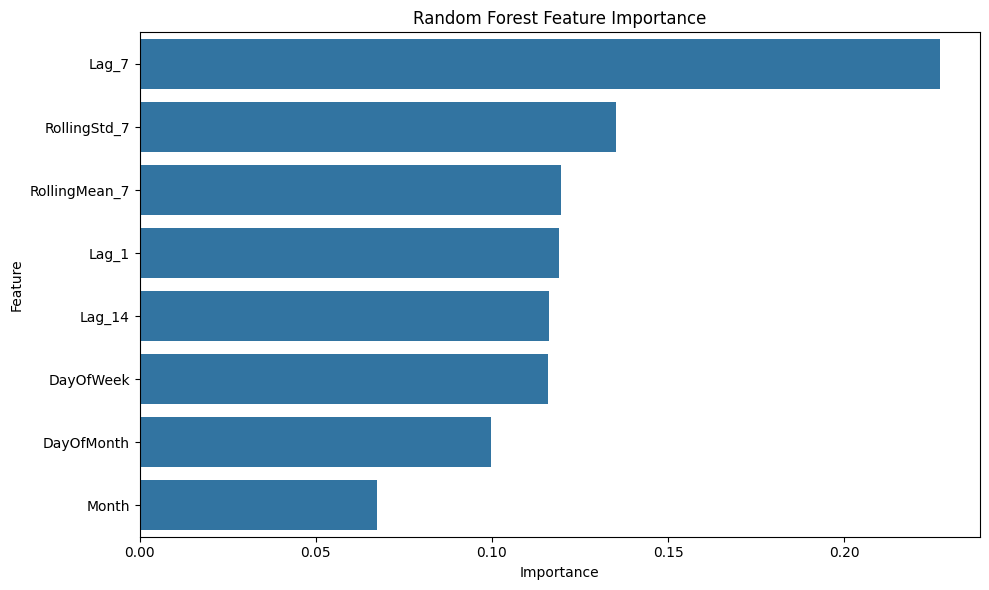

,Feature,Importance
1,Lag_7,0.227214
4,RollingStd_7,0.135164
3,RollingMean_7,0.119753
0,Lag_1,0.118963
2,Lag_14,0.116187
5,DayOfWeek,0.115818
7,DayOfMonth,0.099612
6,Month,0.067288


In [8]:
# Analyze feature importance

from sklearn.inspection import permutation_importance

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": baseline_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

display(importance_df)

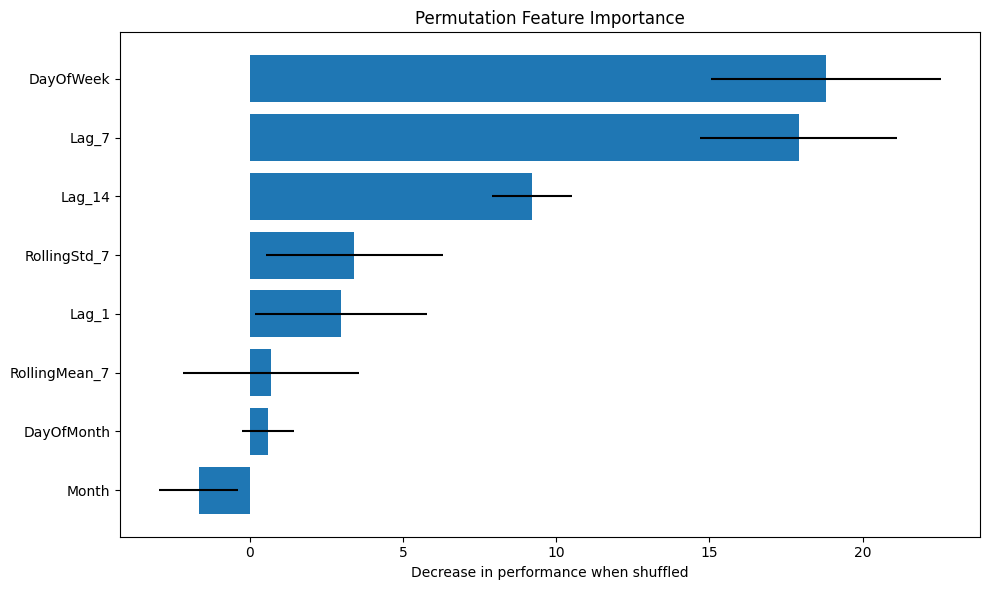

,Feature,Importance,Std
5,DayOfWeek,18.795461,3.753504
1,Lag_7,17.905913,3.207900
2,Lag_14,9.217346,1.309510
4,RollingStd_7,3.417254,2.897695
0,Lag_1,2.982541,2.800411
3,RollingMean_7,0.697652,2.866509
7,DayOfMonth,0.603625,0.841108
6,Month,-1.662420,1.286386


In [9]:
perm = permutation_importance(
    baseline_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(
    permutation_df["Feature"][::-1],
    permutation_df["Importance"][::-1],
    xerr=permutation_df["Std"][::-1]
)
plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in performance when shuffled")
plt.tight_layout()
plt.show()

display(permutation_df)

In [10]:
# Tune Random Forest with Optuna

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=100),
        "max_depth": trial.suggest_int("max_depth", 4, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_float("max_features", 0.5, 1.0),
        "random_state": 42,
        "n_jobs": -1
    }

    model = RandomForestRegressor(**params)

    tscv = TimeSeriesSplit(n_splits=5)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    return -scores.mean()


study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("Best cross-validation MAE:", round(study.best_value, 2))
print("Best parameters:")
print(study.best_params)

[I 2026-10-26 10:03:16,022] A new study created in memory with name: no-name-ef883906-158a-4c39-8666-2b8b51c5099e
[I 2026-10-26 10:03:20,954] Trial 0 finished with value: 113.12346570223436 and parameters: {'n_estimators': 300, 'max_depth': 7, 'min_samples_split': 17, 'min_samples_leaf': 6, 'max_features': 0.9457067456497715}. Best is trial 0 with value: 113.12346570223436.
[I 2026-10-26 10:03:24,162] Trial 1 finished with value: 114.52913318949261 and parameters: {'n_estimators': 300, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 5, 'max_features': 0.8735956789834122}. Best is trial 0 with value: 113.12346570223436.
[I 2026-10-26 10:03:26,420] Trial 2 finished with value: 113.13145771593436 and parameters: {'n_estimators': 200, 'max_depth': 14, 'min_samples_split': 20, 'min_samples_leaf': 3, 'max_features': 0.7624320213504701}. Best is trial 0 with value: 113.12346570223436.
[I 2026-10-26 10:03:27,591] Trial 3 finished with value: 113.68422420095017 and parameters: {'n_e

Best cross-validation MAE: 111.99
Best parameters:
{'n_estimators': 100, 'max_depth': 12, 'min_samples_split': 9, 'min_samples_leaf': 10, 'max_features': 0.7629555989853929}


In [11]:
#Evaluate the tuned model
best_model = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

tuned_pred = best_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print(f"Tuned MAE:  {tuned_mae:.2f}")
print(f"Tuned RMSE: {tuned_rmse:.2f}")
print(f"Tuned R²:   {tuned_r2:.4f}")

comparison = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Optuna-Tuned Random Forest"],
    "MAE": [baseline_mae, tuned_mae],
    "RMSE": [baseline_rmse, tuned_rmse]
})

display(comparison)

Tuned MAE:  124.13
Tuned RMSE: 219.90
Tuned R²:   0.0991


,Model,MAE,RMSE
0,Baseline Random Forest,132.514323,222.606265
1,Optuna-Tuned Random Forest,124.132481,219.899517


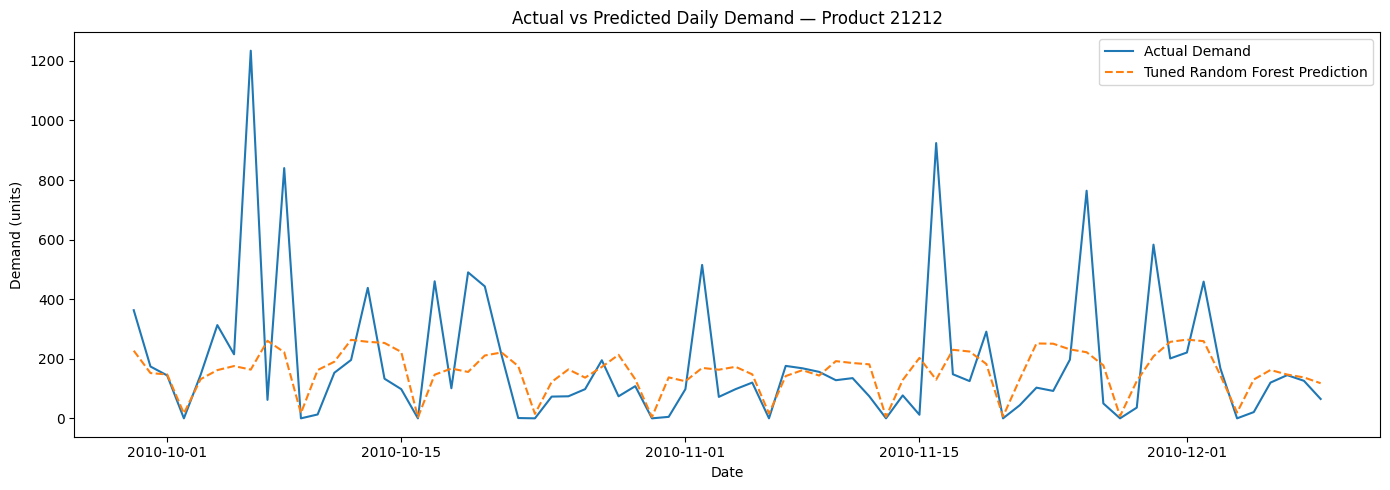

In [12]:
# Plot actual versus predicted demand

plt.figure(figsize=(14, 5))

plt.plot(
    test_df.index,
    y_test,
    label="Actual Demand"
)

plt.plot(
    test_df.index,
    tuned_pred,
    label="Tuned Random Forest Prediction",
    linestyle="--"
)

plt.title(f"Actual vs Predicted Daily Demand — Product {selected_product}")
plt.xlabel("Date")
plt.ylabel("Demand (units)")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Save the model and results

import joblib
import os

output_dir = str(PROJECT_DIR / "optuna_outputs")
os.makedirs(output_dir, exist_ok=True)

joblib.dump(best_model, os.path.join(output_dir, "tuned_random_forest.pkl"))

importance_df.to_csv(
    os.path.join(output_dir, "feature_importance.csv"),
    index=False
)

permutation_df.to_csv(
    os.path.join(output_dir, "permutation_importance.csv"),
    index=False
)

comparison.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

joblib.dump(
    study,
    os.path.join(output_dir, "optuna_study.pkl")
)

print("Model and analysis results saved to:", output_dir)

Model and analysis results saved to: /content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/optuna_outputs
